# ¿Qué hace que una película gane dinero?
**Análisis exploratorio de 3.201 películas** (presupuesto, recaudación, género, valoraciones y distribuidora).

**Pregunta de negocio.** Si un estudio tuviera que decidir en qué películas invertir, ¿qué patrones separan las que recuperan su presupuesto de las que no?

**Preguntas concretas**
1. ¿Qué géneros tienen mejor tasa de éxito y rentabilidad?
2. ¿Cómo cambia el riesgo según el presupuesto?
3. ¿Se relaciona la calidad percibida (IMDB) con el resultado económico?
4. ¿Cuánto depende el negocio de unos pocos éxitos?
5. ¿Qué distribuidoras son más rentables?

**Fuente.** Dataset `movies.json` del repositorio público [vega-datasets](https://github.com/vega/vega-datasets). Datos recopilados hacia 2010; las cifras están en dólares sin ajustar por inflación.

**Definiciones.** `ROI = (recaudación mundial − presupuesto) / presupuesto`. Un ROI de 1,0 significa que recaudó el doble de lo que costó. Una película es *éxito* si su ROI es mayor que 0.

In [1]:
import sys, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path("..") / "src"))
import clean   # nuestro script de limpieza

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
FIG = Path("..") / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
clean.RAW = Path("..") / clean.RAW

## 1. Calidad de los datos

In [2]:
raw = pd.read_json(clean.RAW)
print(f"Filas: {len(raw):,} | Columnas: {raw.shape[1]}")
nulos = (raw.isna().mean() * 100).round(1).sort_values(ascending=False).rename("% nulos")
nulos[nulos > 0].to_frame()

Filas: 3,201 | Columnas: 16


,% nulos
US DVD Sales,82.40
Running Time min,62.20
Director,41.60
Rotten Tomatoes Rating,27.50
MPAA Rating,18.90
Creative Type,13.90
Source,11.40
Major Genre,8.60
Distributor,7.20
IMDB Rating,6.70


Hay columnas con muchos nulos (`US DVD Sales`, `Running Time min`, `Director`), que no usaremos. Las que sí necesitamos (presupuesto y recaudación) están casi completas.

Una comprobación importante antes de nada: **las fechas**. Están guardadas como texto (`Jun 12 1998`), y conviene mirar el rango de años.

In [3]:
anios_raw = pd.to_datetime(raw["Release Date"], format="%b %d %Y").dt.year
futuras = raw.loc[anios_raw > 2011, ["Title", "Release Date"]].head(6)
print(f"Películas con año posterior a 2011 (imposible, el dataset es de ~2010): {(anios_raw > 2011).sum()}")
futuras

Películas con año posterior a 2011 (imposible, el dataset es de ~2010): 22


,Title,Release Date
9,Duel in the Sun,Dec 31 2046
15,Over the Hill to the Poorhouse,Sep 17 2020
16,Wilson,Aug 01 2044
26,"20,000 Leagues Under the Sea",Dec 24 2016
33,42nd Street,Mar 09 2033
85,Ben-Hur,Dec 30 2025


**Problema detectado:** clásicos como *Gone with the Wind* aparecen estrenados en 2039. Es un error de formato (años de 2 dígitos interpretados como 20xx en lugar de 19xx). Lo corregimos restando 100 años a esas fechas. Además, una recaudación de 0 se trata como *dato desconocido*, no como "no recaudó nada" (por ejemplo, películas aún no estrenadas cuando se recopilaron los datos).

## 2. Limpieza

In [4]:
df = clean.load_and_clean()
print(f"{len(df):,} películas | fechas corregidas: {df['fixed_future_date'].sum()} | "
      f"analizables (presupuesto >= 1 M$ y recaudación conocida): {df['analysable'].sum():,}")
df.loc[df["fixed_future_date"], ["title", "release_date"]].head(5)

3,201 películas | fechas corregidas: 22 | analizables (presupuesto >= 1 M$ y recaudación conocida): 2,958


,title,release_date
0,The Birth of a Nation,1915-02-08
1,Intolerance,1916-09-05
2,"20,000 Leagues Under the Sea",1916-12-24
3,Over the Hill to the Poorhouse,1920-09-17
4,The Big Parade,1925-01-01


## 3. ¿Con qué películas analizamos? (sesgo de supervivencia)

In [5]:
a_all = df[df["analysable"]]
dec = (a_all.groupby("decade")
       .agg(peliculas=("title", "count"), roi_mediano=("roi", "median"), pct_exito=("is_hit", "mean"))
       .assign(pct_exito=lambda d: d["pct_exito"] * 100))
dec

,peliculas,roi_mediano,pct_exito
decade,,,
1920,1,1.31,100.00
1930,9,3.66,88.89
1940,16,2.65,87.50
1950,31,3.87,100.00
1960,59,2.80,81.36
1970,82,3.90,84.15
1980,244,1.91,76.64
1990,729,0.67,62.96
2000,1697,0.64,64.43


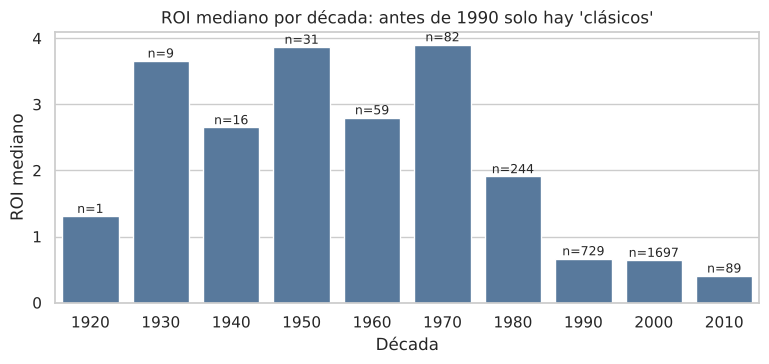

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=dec.reset_index(), x="decade", y="roi_mediano", color="#4C78A8", ax=ax)
for i, (n, v) in enumerate(zip(dec["peliculas"], dec["roi_mediano"])):
    ax.text(i, v + 0.05, f"n={n}", ha="center", fontsize=9)
ax.set(title="ROI mediano por década: antes de 1990 solo hay 'clásicos'", xlabel="Década", ylabel="ROI mediano")
plt.tight_layout(); plt.savefig(FIG / "01_roi_decada.png", dpi=150); plt.show()

Antes de 1990 el ROI mediano parece espectacular (entre 2,6 y 3,9 de 1930 a 1970) pero con muy pocas películas por década (de 1 a 82). Es **sesgo de supervivencia**: el dataset solo recoge títulos antiguos que se siguen recordando, y esos casi siempre fueron éxitos. Compararlos con las películas de los 2000 sería engañoso.

**Decisión:** el análisis principal usa **1990–2010**, donde hay cobertura amplia (más de 2.400 películas).

In [7]:
a = df[df["analysable"] & df["year"].between(1990, 2010)].copy()
print(f"Conjunto de análisis: {len(a):,} películas ({a['year'].min()}-{a['year'].max()})")
kpis = pd.Series({
    "Películas": len(a),
    "Tasa de éxito (ROI > 0)": f"{a['is_hit'].mean():.1%}",
    "ROI mediano": f"{a['roi'].median():.2f}",
    "Recaudación total (mil M$)": f"{a['worldwide_gross'].sum() / 1e9:,.0f}",
})
kpis.to_frame("valor")

Conjunto de análisis: 2,516 películas (1990-2010)


,valor
Películas,2516
Tasa de éxito (ROI > 0),63.9%
ROI mediano,0.64
Recaudación total (mil M$),243


## 4. ¿Qué géneros funcionan mejor?

In [8]:
g = (a[a["major_genre"] != "Unknown"].groupby("major_genre")
     .agg(peliculas=("title", "count"), roi_mediano=("roi", "median"),
          pct_exito=("is_hit", "mean"), presupuesto_mediano=("production_budget", "median"))
     .query("peliculas >= 30").assign(pct_exito=lambda d: d["pct_exito"] * 100)
     .sort_values("pct_exito", ascending=False))
g

,peliculas,roi_mediano,pct_exito,presupuesto_mediano
major_genre,,,,
Adventure,231,1.48,80.95,"70,000,000.00"
Horror,152,1.50,78.95,"17,000,000.00"
Romantic Comedy,130,1.02,70.77,"24,500,000.00"
Action,340,0.83,69.12,"55,000,000.00"
Thriller/Suspense,211,0.49,67.45,"30,000,000.00"
Black Comedy,33,0.38,66.67,"10,000,000.00"
Comedy,586,0.71,65.53,"22,000,000.00"
Drama,667,0.24,55.62,"18,000,000.00"


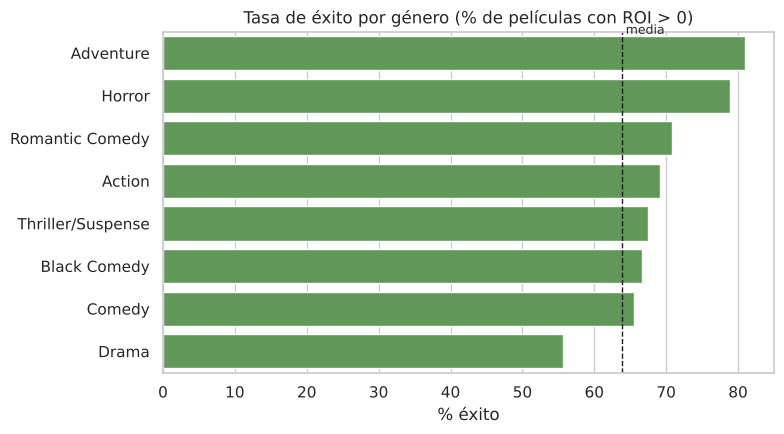

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=g.reset_index(), y="major_genre", x="pct_exito", color="#59A14F", ax=ax)
ax.axvline(a["is_hit"].mean() * 100, color="k", ls="--", lw=1)
ax.text(a["is_hit"].mean() * 100 + 0.5, -0.45, "media", fontsize=9)
ax.set(title="Tasa de éxito por género (% de películas con ROI > 0)", xlabel="% éxito", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "02_exito_genero.png", dpi=150); plt.show()

**Lectura.** Horror (79%) y Adventure (81%) superan claramente la media (64%); Drama es el más flojo (56%). Terror destaca con un presupuesto mediano moderado (17 M$): no hace falta una recaudación enorme para recuperar la inversión. Ojo con el género como explicación única: Adventure tiene un presupuesto mediano de 70 M$, así que género y presupuesto están mezclados (ver sección 5). Y conviene mirar la **mediana** y no la media: en Terror, unos pocos éxitos enormes elevan el ROI medio a 3,1 frente a un mediano de 1,5.

## 5. Presupuesto y riesgo

In [10]:
a["tramo_presupuesto"] = pd.qcut(a["production_budget"], 4,
                                 labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
b = (a.groupby("tramo_presupuesto", observed=True)
     .agg(peliculas=("title", "count"),
          presupuesto_desde=("production_budget", "min"),
          roi_mediano=("roi", "median"),
          pct_exito=("is_hit", "mean"),
          peor_10pct=("roi", lambda s: s.quantile(0.10)),
          mejor_10pct=("roi", lambda s: s.quantile(0.90)))
     .assign(pct_exito=lambda d: d["pct_exito"] * 100))
b

,peliculas,presupuesto_desde,roi_mediano,pct_exito,peor_10pct,mejor_10pct
tramo_presupuesto,,,,,,
Q1 (bajo),632,"1,000,000.00",0.39,57.82,-0.97,7.70
Q2,663,"11,900,000.00",0.46,59.73,-0.84,5.11
Q3,609,"25,100,000.00",0.50,62.56,-0.69,4.40
Q4 (alto),611,"51,000,000.00",1.02,75.94,-0.45,4.12


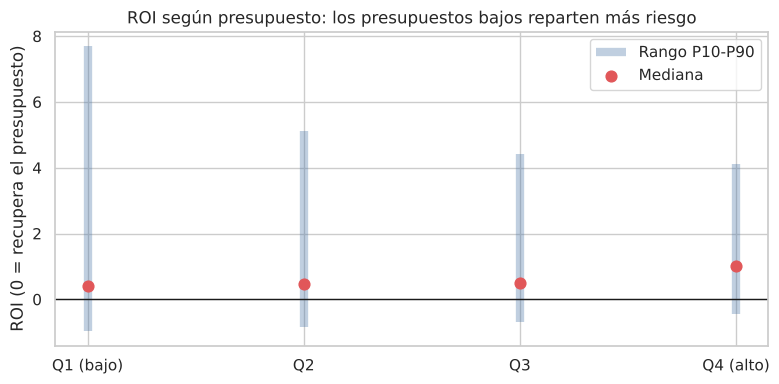

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(b))
ax.vlines(x, b["peor_10pct"], b["mejor_10pct"], color="#4C78A8", lw=6, alpha=0.35, label="Rango P10-P90")
ax.scatter(x, b["roi_mediano"], color="#E15759", zorder=3, s=60, label="Mediana")
ax.axhline(0, color="k", lw=1)
ax.set_xticks(x, b.index)
ax.set(title="ROI según presupuesto: los presupuestos bajos reparten más riesgo",
       ylabel="ROI (0 = recupera el presupuesto)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "03_roi_presupuesto.png", dpi=150); plt.show()

**Lectura.** Las películas de presupuesto bajo (Q1) tienen el ROI mediano más bajo (0,39) y la mayor dispersión: el 10% peor pierde casi todo lo invertido (ROI −0,97) mientras el 10% mejor llega a 7,7. Las de presupuesto alto (Q4) tienen la **mayor tasa de éxito (76%)**, el ROI mediano más alto (1,02) y la menor pérdida en el peor 10% (−0,45). Apostar por baratas se parece a una lotería con premios altos; las grandes producciones fallan menos. Matiz: las películas caras también son las que más se distribuyen y se promocionan, y eso no lo recoge el dataset.

## 6. ¿Importa la calidad percibida?

In [12]:
q = a.dropna(subset=["imdb_rating"]).copy()
q["tramo_imdb"] = pd.cut(q["imdb_rating"], [0, 5.5, 6.5, 7.5, 10],
                         labels=["< 5,5", "5,5–6,5", "6,5–7,5", "> 7,5"])
c = (q.groupby("tramo_imdb", observed=True)
     .agg(peliculas=("title", "count"), roi_mediano=("roi", "median"),
          pct_exito=("is_hit", "mean"), recaudacion_mediana=("worldwide_gross", "median"))
     .assign(pct_exito=lambda d: d["pct_exito"] * 100))
display(c)
rho = q[["imdb_rating", "roi"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman IMDB vs ROI: {rho:.2f}")

,peliculas,roi_mediano,pct_exito,recaudacion_mediana
tramo_imdb,,,,
"< 5,5",625,0.24,56.00,"30,143,795.00"
"5,5–6,5",724,0.36,58.70,"41,172,167.00"
"6,5–7,5",714,0.83,67.55,"41,610,884.00"
"> 7,5",303,2.29,83.17,"71,430,876.00"


Correlación de Spearman IMDB vs ROI: 0.25


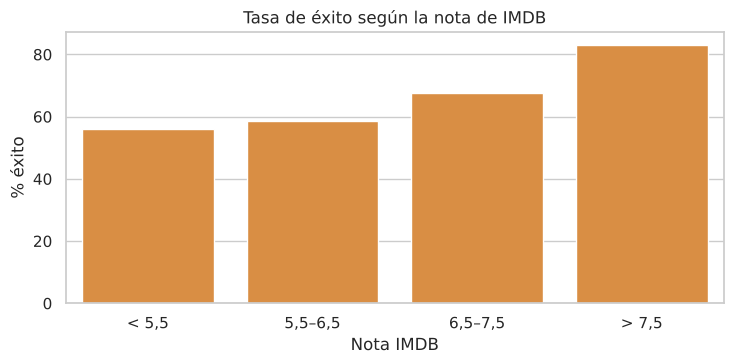

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.barplot(data=c.reset_index(), x="tramo_imdb", y="pct_exito", color="#F28E2B", ax=ax)
ax.set(title="Tasa de éxito según la nota de IMDB", xlabel="Nota IMDB", ylabel="% éxito")
plt.tight_layout(); plt.savefig(FIG / "04_exito_imdb.png", dpi=150); plt.show()

**Lectura.** Las películas con nota > 7,5 tienen un ROI mediano de 2,3 frente a 0,24 de las de < 5,5 (casi 10 veces más) y un 83% de éxito frente al 56%. La correlación es positiva pero moderada (≈0,25): la calidad **ayuda, pero no lo explica todo**. Importante: es una asociación, no prueba de que mejorar la calidad cause más recaudación (la nota se publica después del estreno y las películas populares reciben más votos).

## 7. ¿Cuánto dependen los resultados de unos pocos éxitos?

El 10% de las películas concentra el 49% de la recaudación; el 1%, el 11%.


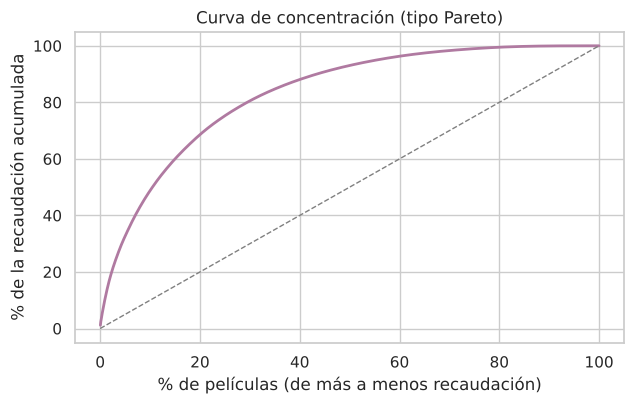

In [14]:
s = a.sort_values("worldwide_gross", ascending=False).reset_index(drop=True)
s["pct_peliculas"] = (s.index + 1) / len(s) * 100
s["pct_recaudacion"] = s["worldwide_gross"].cumsum() / s["worldwide_gross"].sum() * 100
top10 = s.loc[s["pct_peliculas"] <= 10, "pct_recaudacion"].iloc[-1]
top1 = s.loc[s["pct_peliculas"] <= 1, "pct_recaudacion"].iloc[-1]
print(f"El 10% de las películas concentra el {top10:.0f}% de la recaudación; el 1%, el {top1:.0f}%.")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(s["pct_peliculas"], s["pct_recaudacion"], color="#B07AA1", lw=2)
ax.plot([0, 100], [0, 100], color="gray", ls="--", lw=1)
ax.set(title="Curva de concentración (tipo Pareto)", xlabel="% de películas (de más a menos recaudación)",
       ylabel="% de la recaudación acumulada")
plt.tight_layout(); plt.savefig(FIG / "05_concentracion.png", dpi=150); plt.show()

**Lectura.** El 10% de las películas aporta casi la mitad de toda la recaudación. Un estudio que no tenga algún éxito grande en su cartera difícilmente compensa sus fracasos.

## 8. Distribuidoras y consultas SQL

Para practicar SQL sobre los mismos datos, cargamos el conjunto analizable en una base SQLite en memoria y ejecutamos las consultas de `sql/queries.sql` (agregaciones, CTE y funciones de ventana).

In [15]:
con = sqlite3.connect(":memory:")
cols = ["title", "year", "major_genre", "distributor", "production_budget",
        "worldwide_gross", "profit", "roi", "is_hit"]
a[cols].to_sql("movies", con, index=False)

def run(name):
    text = (Path("..") / "sql" / "queries.sql").read_text(encoding="utf-8")
    block = text.split(f"-- name: {name}")[1].split("-- Q")[0]
    return pd.read_sql(block, con)

run("genero_exito")

,major_genre,peliculas,pct_exito,roi_medio,recaudacion_mm_usd
0,Adventure,231,81.00,2.36,60.33
1,Horror,152,78.90,3.13,10.27
2,Romantic Comedy,130,70.80,3.01,11.82
3,Action,340,69.10,1.37,53.98
4,Thriller/Suspense,212,67.50,1.31,18.55
5,Black Comedy,33,66.70,1.43,0.81
6,Comedy,586,65.50,1.94,46.16
7,Drama,667,55.60,1.59,36.34


In [16]:
run("peso_distribuidoras")

,distributor,peliculas,recaudacion_mm_usd,pct_total,pct_acumulado
0,Warner Bros.,271,36.80,15.20,15.20
1,Walt Disney Pictures,218,34.00,14.00,29.20
2,Sony Pictures,287,31.15,12.90,42.10
3,20th Century Fox,191,30.54,12.60,54.70
4,Paramount Pictures,206,29.13,12.00,66.70
5,Universal,197,26.07,10.80,77.40
6,New Line,128,11.27,4.70,82.10
7,Dreamworks SKG,53,7.83,3.20,85.30


In [17]:
run("top3_por_genero")

,major_genre,rk,title,year,beneficio_m_usd
0,Action,1,Avatar,2009,"2,530.90"
1,Action,2,Jurassic Park,1993,860.10
2,Action,3,The Dark Knight,2008,837.30
3,Comedy,1,Aladdin,1992,476.10
4,Comedy,2,Ratatouille,2007,470.50
5,Comedy,3,Night at the Museum,2006,464.50
6,Drama,1,The Twilight Saga: New Moon,2009,652.60
7,Drama,2,Forrest Gump,1994,624.40
8,Drama,3,The Twilight Saga: Eclipse,2010,620.20
9,Horror,1,I am Legend,2007,435.10


In [18]:
run("evolucion_anual").tail(8)

,year,peliculas,recaudacion_mm_usd,var_pct
13,2003,171,15.56,-3.50
14,2004,177,17.92,15.20
15,2005,190,17.15,-4.30
16,2006,200,17.06,-0.50
17,2007,152,16.91,-0.90
18,2008,149,16.37,-3.20
19,2009,123,19.58,19.60
20,2010,89,11.65,-40.50


In [19]:
d = (a[a["distributor"] != "Unknown"].groupby("distributor")
     .agg(peliculas=("title", "count"), recaudacion=("worldwide_gross", "sum"),
          roi_mediano=("roi", "median"), pct_exito=("is_hit", "mean"))
     .query("peliculas >= 50").assign(pct_exito=lambda t: t["pct_exito"] * 100)
     .sort_values("roi_mediano", ascending=False))
d["recaudacion"] = (d["recaudacion"] / 1e9).round(1)
d.rename(columns={"recaudacion": "recaudacion_mm_usd"})

,peliculas,recaudacion_mm_usd,roi_mediano,pct_exito
distributor,,,,
Fox Searchlight,58,2.20,1.40,68.97
Lionsgate,79,3.40,1.35,75.95
20th Century Fox,191,30.50,1.30,76.44
Walt Disney Pictures,218,34.00,1.08,71.10
Universal,197,26.10,0.94,71.57
Paramount Pictures,206,29.10,0.94,73.30
Sony Pictures,287,31.10,0.83,69.34
Dreamworks SKG,53,7.80,0.79,71.70
New Line,128,11.30,0.75,67.19


**Lectura.** Fox (ROI mediano 1,30) y Disney (1,08) combinan volumen alto con buen rendimiento; Warner Bros. es la que más recauda en total (36,8 mil M$) pero con un ROI mediano menor (0,64). Las distribuidoras de cine independiente, como Sony Pictures Classics, tienen ROI negativo en este dataset. Con `n ≥ 50` evitamos sacar conclusiones de distribuidoras con muy pocas películas.

## 9. Conclusiones y recomendaciones

1. **Género:** Adventure (81%) y Horror (79%) son los de mejor tasa de éxito; Drama (56%) es el más flojo.
2. **Presupuesto:** las de presupuesto alto tienen la mayor tasa de éxito (76%) y el ROI mediano más alto (1,02); las de presupuesto bajo son una lotería (el 10% peor pierde casi todo, el 10% mejor llega a 7,7).
3. **Calidad:** una nota IMDB > 7,5 se asocia con un ROI mediano de 2,3 y un 83% de éxito, frente a 0,24 y 56% de las < 5,5; la relación no es determinante.
4. **Concentración:** el 10% de películas aporta ~49% de la recaudación; el negocio vive de unos pocos grandes éxitos.
5. **Sesgo:** los datos antiguos (< 1990) solo incluyen clásicos supervivientes y distorsionan cualquier comparación temporal.

**Si fuera una decisión de inversión**, estos datos sugieren priorizar géneros de alta tasa de éxito (aventura, terror) con presupuestos medios-altos y limitar las apuestas de bajo presupuesto a una parte pequeña de la cartera, sabiendo que dan pocos aciertos pero grandes.

## 10. Limitaciones
- **Recaudación no es beneficio.** La recaudación mundial incluye la parte que se quedan los cines y no incluye marketing ni ingresos de DVD/streaming. El ROI aquí es un indicador comparativo, no el beneficio contable.
- **Dólares sin ajustar por inflación**, por lo que comparar décadas distintas es aproximado.
- **Datos hasta ~2010**: no reflejan el streaming ni el mercado actual.
- **Sesgo de supervivencia** en películas anteriores a 1990 y datos faltantes en género y distribuidora (se agrupan como "Unknown").
- Todo lo anterior son **asociaciones**, no causalidad.